	Predicting Stock Market Prices	Systematically partition the TSLA dataset into temporally consistent training and testing subsets using an 80/20 time-based split, maintaining chronological order to prevent data leakage and ensure robust model evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit

In [2]:
# Load dataset and sort strictly by chronological Date
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Audit and deduplicate repeated trading dates (prevents same-day leakage across split boundaries)
dup_count = df.duplicated(subset=['Date']).sum()
print(f"Raw Rows: {len(df)} | Unique Trading Dates: {df['Date'].nunique()} (Duplicate rows removed: {dup_count})")

df = df.drop_duplicates(subset=['Date'], keep='last').reset_index(drop=True)
print(f"Clean Chronological Dataset: {len(df)} trading days ({df['Date'].min().date()} to {df['Date'].max().date()})")

Raw Rows: 100 | Unique Trading Dates: 95 (Duplicate rows removed: 5)
Clean Chronological Dataset: 95 trading days (2025-01-02 to 2025-05-14)


In [3]:
# Build supervised forecasting features strictly from past observations (t-1 and earlier)
df['Close_Lag_1'] = df['Close'].shift(1)
df['Close_Lag_2'] = df['Close'].shift(2)
df['Close_Lag_5'] = df['Close'].shift(5)
df['EMA_7_Past'] = df['Close'].shift(1).ewm(span=7, adjust=False).mean()
df['SMA_10_Past'] = df['Close'].shift(1).rolling(window=10).mean()
df['Log_Return_Lag_1'] = np.log(df['Close'].shift(1) / df['Close'].shift(2))

# Drop initial warm-up rows so X and y are completely NaN-free
df_model = df.dropna().reset_index(drop=True)

feature_cols = ['Close_Lag_1', 'Close_Lag_2', 'Close_Lag_5', 'EMA_7_Past', 'SMA_10_Past', 'Log_Return_Lag_1']
target_col = 'Close'

# Systematic 80/20 Chronological Split (NO shuffling)
split_ratio = 0.80
split_idx = int(len(df_model) * split_ratio)

train_df = df_model.iloc[:split_idx].copy()
test_df = df_model.iloc[split_idx:].copy()

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

# Programmatic Leakage & Temporal Integrity Assertions
assert train_df['Date'].max() < test_df['Date'].min(), "LEAKAGE ERROR: Train and Test dates overlap!"
assert len(train_df) + len(test_df) == len(df_model), "ROW MISMATCH: Partition sizes do not sum to dataset!"

print("--- 80/20 Chronological Train/Test Split Summary ---")
print(f"Total Modeling Rows : {len(df_model)}")
print(f"Training Set (80%)  : {len(train_df)} rows | {train_df['Date'].min().date()} -> {train_df['Date'].max().date()}")
print(f"Testing Set  (20%)  : {len(test_df)} rows | {test_df['Date'].min().date()} -> {test_df['Date'].max().date()}")
print(f"Temporal Gap        : {(test_df['Date'].min() - train_df['Date'].max()).days} calendar days (weekend/market break)")

--- 80/20 Chronological Train/Test Split Summary ---
Total Modeling Rows : 85
Training Set (80%)  : 68 rows | 2025-01-16 -> 2025-04-21
Testing Set  (20%)  : 17 rows | 2025-04-22 -> 2025-05-14
Temporal Gap        : 1 calendar days (weekend/market break)


In [4]:
# Compare Target (Close Price) Statistics across Training vs. Testing Subsets
split_stats = pd.DataFrame({
    'Subset': ['Training (80%)', 'Testing (20%)'],
    'Samples': [len(y_train), len(y_test)],
    'Start_Date': [train_df['Date'].min().date(), test_df['Date'].min().date()],
    'End_Date': [train_df['Date'].max().date(), test_df['Date'].max().date()],
    'Mean_Close ($)': [y_train.mean(), y_test.mean()],
    'Std_Close ($)': [y_train.std(), y_test.std()],
    'Min_Close ($)': [y_train.min(), y_test.min()],
    'Max_Close ($)': [y_train.max(), y_test.max()]
})

print("--- Target Distribution Across Temporal Partitions ---")
print(split_stats.round(2).to_string(index=False))

# Fit scaler strictly on X_train, then transform X_test (prevents future mean/std leakage)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_cols, index=X_test.index)

print("\nScaled X_train mean (approx 0):", X_train_scaled.mean().round(4).to_dict())
print("Scaled X_test  mean (shifted) :", X_test_scaled.mean().round(4).to_dict())

--- Target Distribution Across Temporal Partitions ---
        Subset  Samples Start_Date   End_Date  Mean_Close ($)  Std_Close ($)  Min_Close ($)  Max_Close ($)
Training (80%)       68 2025-01-16 2025-04-21          398.23          13.56         368.58         420.55
 Testing (20%)       17 2025-04-22 2025-05-14          402.91           4.63         394.85         410.03

Scaled X_train mean (approx 0): {'Close_Lag_1': -0.0, 'Close_Lag_2': 0.0, 'Close_Lag_5': 0.0, 'EMA_7_Past': -0.0, 'SMA_10_Past': 0.0, 'Log_Return_Lag_1': -0.0}
Scaled X_test  mean (shifted) : {'Close_Lag_1': 0.4191, 'Close_Lag_2': 0.4444, 'Close_Lag_5': 0.485, 'EMA_7_Past': 0.5381, 'SMA_10_Past': 0.5704, 'Log_Return_Lag_1': -0.1374}


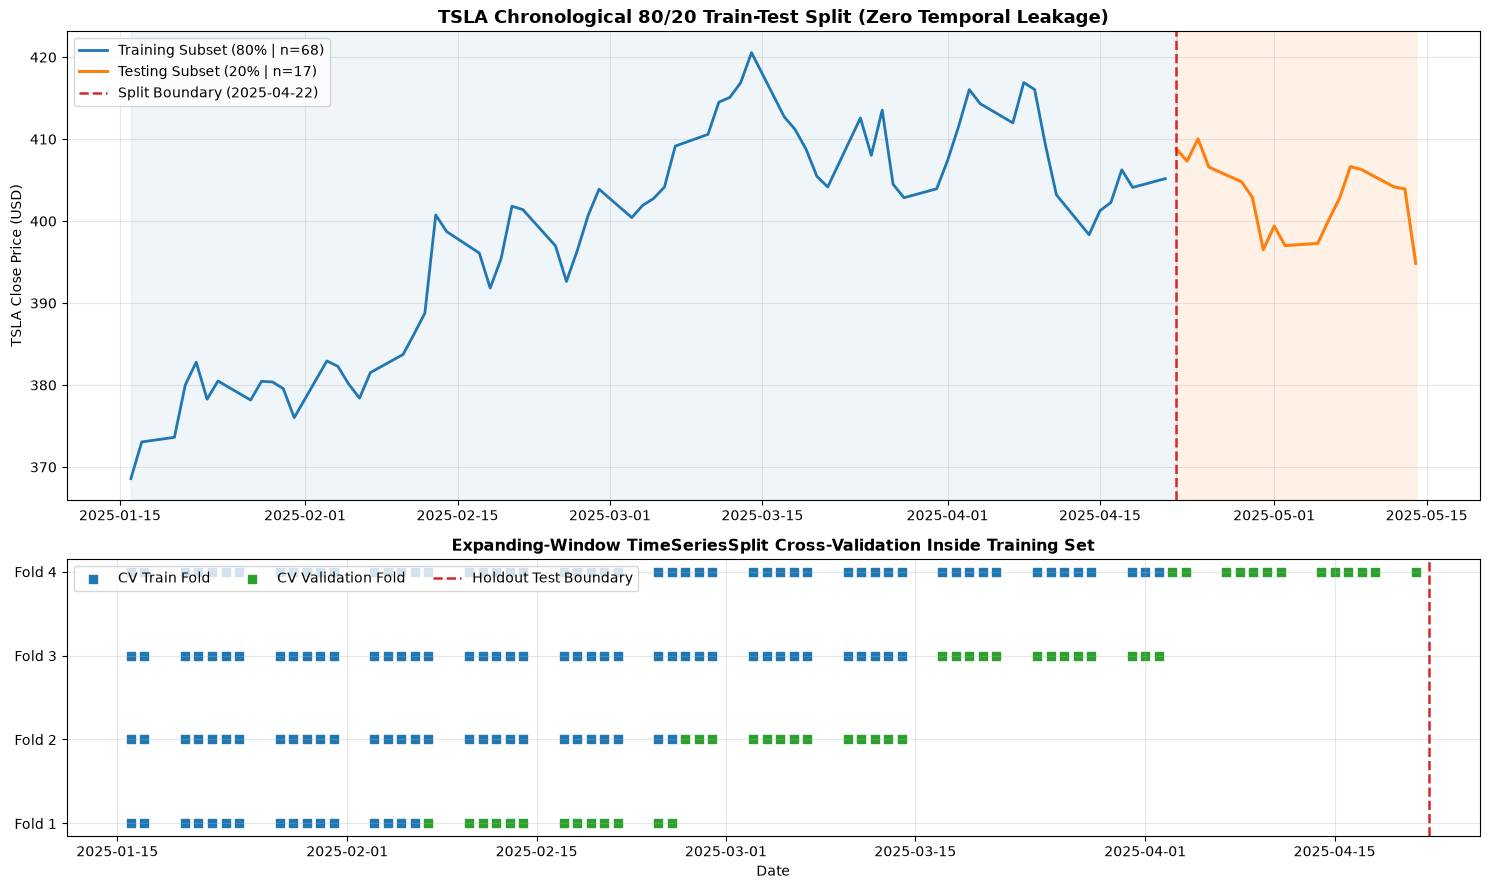

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9), gridspec_kw={'height_ratios': [2.2, 1.3]})

# Panel 1: Chronological 80/20 Train-Test Partition on TSLA Close Price
cutoff_date = test_df['Date'].min()
ax1.plot(train_df['Date'], y_train, color='#1f77b4', linewidth=2, label=f'Training Subset (80% | n={len(train_df)})')
ax1.plot(test_df['Date'], y_test, color='#ff7f0e', linewidth=2.2, label=f'Testing Subset (20% | n={len(test_df)})')
ax1.axvline(cutoff_date, color='#d62728', linestyle='--', linewidth=1.8, label=f'Split Boundary ({cutoff_date.date()})')
ax1.axvspan(train_df['Date'].min(), cutoff_date, color='#1f77b4', alpha=0.07)
ax1.axvspan(cutoff_date, test_df['Date'].max(), color='#ff7f0e', alpha=0.10)

ax1.set_title('TSLA Chronological 80/20 Train-Test Split (Zero Temporal Leakage)', fontsize=13, fontweight='bold')
ax1.set_ylabel('TSLA Close Price (USD)')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# Panel 2: Expanding-Window TimeSeriesSplit (4 Folds inside Training Set for Hyperparameter Tuning)
tscv = TimeSeriesSplit(n_splits=4)
for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train), start=1):
    ax2.scatter(train_df['Date'].iloc[tr_idx], [fold] * len(tr_idx), color='#1f77b4', marker='s', s=28,
                label='CV Train Fold' if fold == 1 else "")
    ax2.scatter(train_df['Date'].iloc[val_idx], [fold] * len(val_idx), color='#2ca02c', marker='s', s=28,
                label='CV Validation Fold' if fold == 1 else "")

ax2.axvline(cutoff_date, color='#d62728', linestyle='--', linewidth=1.8, label='Holdout Test Boundary')
ax2.set_yticks([1, 2, 3, 4])
ax2.set_yticklabels([f'Fold {i}' for i in range(1, 5)])
ax2.set_title('Expanding-Window TimeSeriesSplit Cross-Validation Inside Training Set', fontsize=11.5, fontweight='bold')
ax2.set_xlabel('Date')
ax2.legend(loc='upper left', ncol=3)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()